# DeepJSCC + NTSCC Windows benchmark (final repaired)

This notebook is a clean, ordered benchmark. It preserves both official checkpoints, runs native CPU inference on Windows, uses a common image/resolution/SNR/seeds, exercises the team's real 5G-LDPC/QPSK/AWGN path, and only then evaluates two separately calibrated K=256 latent codebooks. Analog symbols, entropy estimates, packet bits, coded bits, and complex channel uses are kept distinct.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
assert Path(sys.prefix).resolve() == (ROOT / '.venv').resolve(), 'Select the semcom-windows kernel created by setup_windows_venv.ps1'
from IPython.display import display, Image as DisplayImage
from semcom_benchmark.session import BenchmarkSession
session = BenchmarkSession(ROOT, snr_db=10.0, seeds=(42, 43, 44, 45, 46), device='cpu')
print(f'Python: {sys.version.split()[0]} | environment: {sys.prefix}')
print(f'Test image: {session.image_path.name}, {session.width}x{session.height}')

Python: 3.13.4 | environment: D:\<local OneDrive>\Desktop\image_semcom\.venv
Test image: kodim08.png, 768x512


## 1. Provenance and strict checkpoint validation

The adapters instantiate checkpoint-compatible official architectures. Learned keys and shapes must match. `strict=False` is never used. Only the six official Swin attention masks listed below may be regenerated for the runtime resolution.

In [2]:
checkpoint_validation = session.load_models()
display(checkpoint_validation)

D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\jit\_script.py:365: FutureWarning: `torch.jit.script_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\n

Encoder  dim=256, input_resolution=(256, 256), depth=1
Encoder  dim=256, input_resolution=(128, 128), depth=1
Encoder  dim=256, input_resolution=(64, 64), depth=2
Encoder  dim=256, input_resolution=(32, 32), depth=4


Decoder  dim=256, input_resolution=(16, 16), depth=4
Decoder  dim=256, input_resolution=(32, 32), depth=2
Decoder  dim=256, input_resolution=(64, 64), depth=1
Decoder  dim=256, input_resolution=(128, 128), depth=1


CONFIG RATE tensor([ 16,  32,  48,  64,  80,  96, 102, 118, 134, 160, 186, 192, 208, 224,
        240, 256])


{'DeepJSCC': {'checkpoint_key_count': 29,
  'missing_keys': [],
  'unexpected_keys': [],
  'shape_mismatches': {},
  'skipped_regenerated_buffers': [],
  'strict_load': True,
  'checkpoint_sha256': '00b33bac630555d9a0d72a76d0fea9103cef9a38df0d5547be53c5320a451d44',
  'source_commit': 'e1cef6aeadedde9ff359760936a2ddf2540dd821'},
 'NTSCC': {'checkpoint_key_count': 426,
  'missing_keys': [],
  'unexpected_keys': [],
  'shape_mismatches': {},
  'skipped_regenerated_buffers': ['ga.layers.2.blocks.1.attn_mask',
   'ga.layers.3.blocks.1.attn_mask',
   'ga.layers.3.blocks.3.attn_mask',
   'gs.layers.0.blocks.1.attn_mask',
   'gs.layers.0.blocks.3.attn_mask',
   'gs.layers.1.blocks.1.attn_mask'],
  'strict_load': True,
  'checkpoint_sha256': '7a8d1990dbd678ea5d3daa02c3aeaaf4459b347a96d6aa81a5c02eae6bfc7323',
  'source_commit': 'dd3c745374023af6d01f465c379122be785d936f'}}

## 2. Official DeepJSCC and NTSCC inference

Both models use the same 768x512 RGB image, evaluation SNR 10 dB, and five noise seeds. DeepJSCC's 128x128 checkpoint is applied by documented reflect-pad/tile/crop; its continuous real channel symbols are paired into complex channel uses. NTSCC entropy BPP remains a diagnostic estimate and is not labeled as radio bits.

In [3]:
native_results = session.run_native_models()
display(native_results[['method','checkpoint_training_snr_db','evaluation_snr_db','complex_channel_uses','cbr','psnr_db_mean','psnr_db_std','ssim_mean','ssim_std','lpips_mean','clip_cosine_mean']])

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\lpips\weights\v0.1\alex.pth


D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\clip\clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging


D:\<local OneDrive>\Desktop\image_semcom\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


,method,checkpoint_training_snr_db,evaluation_snr_db,complex_channel_uses,cbr,psnr_db_mean,psnr_db_std,ssim_mean,ssim_std,lpips_mean,clip_cosine_mean
0,DeepJSCC,200.0,10.0,191748,0.162547,15.983024,0.017816,0.410914,0.001496,0.702314,0.777739
1,NTSCC,10.0,10.0,36126,0.030624,25.705845,0.044682,0.820711,0.000897,0.169477,0.967443


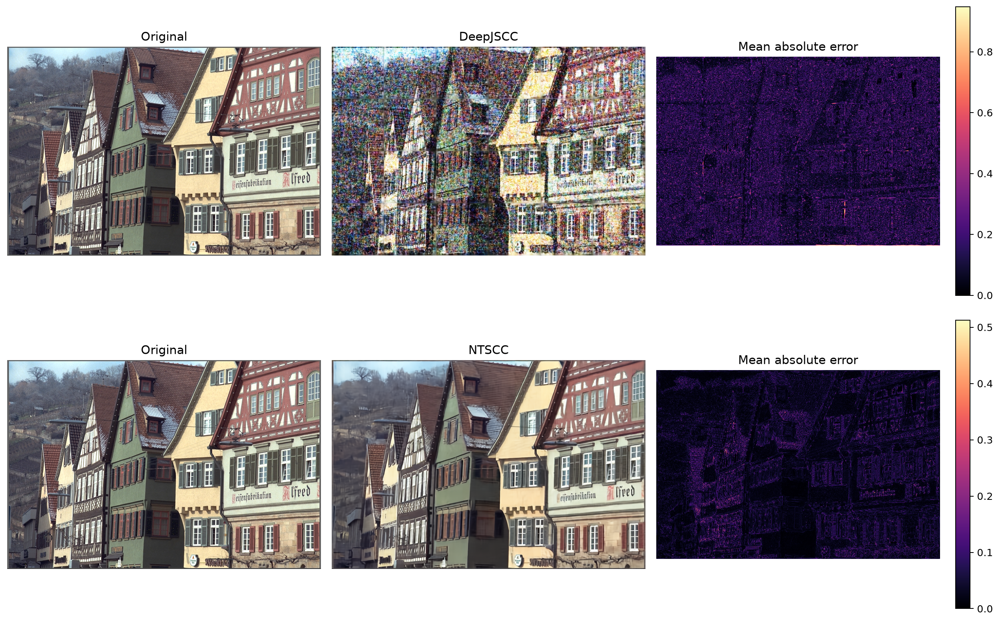

In [4]:
native_plot = session.plot_native_reconstructions()
display(DisplayImage(filename=str(native_plot)))

## 3. RAW/JPEG digital baselines through the team PHY

Payloads are framed with CRC, encoded by the team's Sionna 5G LDPC implementation, QPSK-modulated, passed through AWGN, decoded, and CRC-checked. Quality metrics are recorded only for successful frames. LDPC redundancy is reported separately and is never treated as compression. The very large full-resolution RAW payload uses one auditable CPU trial; every JPEG quality uses all five seeds.

In [5]:
digital_results = session.run_digital_baselines()
display(digital_results[['method','payload_bits','coded_bits','complex_channel_uses','cbr','frame_success_rate','compression_ratio_vs_raw','psnr_db_mean','ssim_mean','lpips_mean','clip_cosine_mean']])

,method,payload_bits,coded_bits,complex_channel_uses,cbr,frame_success_rate,compression_ratio_vs_raw,psnr_db_mean,ssim_mean,lpips_mean,clip_cosine_mean
0,RAW + LDPC/QPSK/AWGN,9437184,18876416,9438208,8.000868,1.0,1.000000,inf,1.000000,0.000000,1.000000
1,JPEG Q90 + LDPC/QPSK/AWGN,1324216,2650112,1325056,1.123264,1.0,7.126620,36.230540,0.973055,0.006834,0.987068
2,JPEG Q75 + LDPC/QPSK/AWGN,813912,1628160,814080,0.690104,1.0,11.594846,32.156016,0.943577,0.018946,0.985519
3,JPEG Q50 + LDPC/QPSK/AWGN,552960,1107968,553984,0.469618,1.0,17.066667,29.425811,0.910267,0.043609,0.972427
4,JPEG Q25 + LDPC/QPSK/AWGN,366488,733184,366592,0.310764,1.0,25.750322,26.841379,0.861148,0.087909,0.951306


In [6]:
pre_codebook_table = session.comparison_table()
display(pre_codebook_table.fillna('N/A'))

,Method,Category,Payload bits,Coded bits,Complex channel uses,CBR,Compression vs RAW,Bit reduction vs RAW (%),Channel-use saving vs RAW (%),Frame success rate,PSNR mean (dB),PSNR std,SSIM mean,LPIPS mean,CLIP cosine mean,Warning
0,RAW image,Source,9437184.0,N/A,N/A,N/A,1.0,0.0,N/A,N/A,inf,0.0,1.000000,0.000000,1.000000,Untransmitted source reference.
1,JPEG Q90,Codec only,1324216.0,N/A,N/A,N/A,7.12662,85.968102,N/A,N/A,36.230540,N/A,0.973055,0.006834,0.987068,Codec distortion only; no channel.
2,JPEG Q75,Codec only,813912.0,N/A,N/A,N/A,11.594846,91.375478,N/A,N/A,32.156016,N/A,0.943577,0.018946,0.985519,Codec distortion only; no channel.
3,JPEG Q50,Codec only,552960.0,N/A,N/A,N/A,17.066667,94.140625,N/A,N/A,29.425811,N/A,0.910267,0.043609,0.972427,Codec distortion only; no channel.
4,JPEG Q25,Codec only,366488.0,N/A,N/A,N/A,25.750322,96.116553,N/A,N/A,26.841379,N/A,0.861148,0.087909,0.951306,Codec distortion only; no channel.
5,RAW + LDPC/QPSK/AWGN,Digital PHY,9437184.0,18876416.0,9438208.0,8.000868,1.0,0.0,0.0,1.0,inf,0.0,1.000000,0.000000,1.000000,Metrics include successful CRC-valid frames on...
6,JPEG Q90 + LDPC/QPSK/AWGN,Digital PHY,1324216.0,2650112.0,1325056.0,1.123264,7.12662,85.968102,85.960725,1.0,36.230540,0.0,0.973055,0.006834,0.987068,Metrics include successful CRC-valid frames on...
7,JPEG Q75 + LDPC/QPSK/AWGN,Digital PHY,813912.0,1628160.0,814080.0,0.690104,11.594846,91.375478,91.374634,1.0,32.156016,0.0,0.943577,0.018946,0.985519,Metrics include successful CRC-valid frames on...
8,JPEG Q50 + LDPC/QPSK/AWGN,Digital PHY,552960.0,1107968.0,553984.0,0.469618,17.066667,94.140625,94.130411,1.0,29.425811,0.0,0.910267,0.043609,0.972427,Metrics include successful CRC-valid frames on...
9,JPEG Q25 + LDPC/QPSK/AWGN,Digital PHY,366488.0,733184.0,366592.0,0.310764,25.750322,96.116553,96.115873,1.0,26.841379,0.0,0.861148,0.087909,0.951306,Metrics include successful CRC-valid frames on...


# 4. Codebook approaches (intentionally after the official comparison)

DeepJSCC and NTSCC receive separate K=256 codebooks fitted only on real CIFAR-10 training-split calibration latents. The test image is never used for fitting, and official encoders/decoders remain frozen. Packets use the team repository format and contain indices, latent metadata, NTSCC rate data where needed, and CRC.

In [7]:
codebook_provenance = session.fit_codebooks(calibration_images=8)
packets = session.prepare_codebook_packets()
display(codebook_provenance)
print({name: packet.bits.size for name, packet in packets.items()})

{'dataset': 'CIFAR-10 training split',
 'dataset_root': 'D:\\<local OneDrive>\\Desktop\\image_semcom\\data',
 'selected_training_indices': [0, 1, 2, 3, 4, 5, 6, 7],
 'calibration_resize': [128, 128],
 'test_image_used_for_fit': False,
 'deepjscc_codebook_sha256': '7924944c1201260256eea1b47bcd990d820f3586ef01a9d6a53d8ae7ea0151c1',
 'ntscc_codebook_sha256': '1adac6882c5f9104436049b64206af40de9ecbaa6263ad1e124716d4c303f789',
 'ntscc_codebook_design': 'K=256 active-prefix product quantization with 16-D blocks',
 'ntscc_calibration_active_block_count': 1129,
 'separate_codebooks': True,
 'official_encoders_decoders_frozen': True,
 'fit_latency_s': 7.569245099963155}

{'DeepJSCC codebook': 161632, 'NTSCC codebook': 42440}


### 4a. Noiseless quantization ablation (first)

In [8]:
noiseless_codebooks = session.run_noiseless_codebook_ablation()
display(noiseless_codebooks)

,method,experiment,packet_bits,shared_codebook_storage_bits,quantization_mse,latency_s,codebook_utilization,used_entries,dead_entries,perplexity,mse,psnr_db,ssim,lpips,clip_cosine
0,DeepJSCC codebook,noiseless quantization ablation,161632,155648,0.038758,0.830407,0.925781,237,19,125.459049,0.018989,17.214867,0.393513,0.609005,0.611349
1,NTSCC codebook,noiseless quantization ablation,42440,131072,2.122081,4.612358,0.988281,253,3,192.832008,0.041617,13.807251,0.383858,0.517441,0.608645


### 4b. Real codebook packets through LDPC/QPSK/AWGN (second)

All five seeds are retained. CRC/frame failures remain failures with N/A reconstruction quality; they are never replaced by codec-only results.

In [9]:
noisy_codebooks = session.run_noisy_codebook_transport()
display(noisy_codebooks[['method','packet_bits','coded_bits','complex_channel_uses','cbr','frame_success_rate','codebook_utilization','dead_entries','perplexity','quantization_mse','psnr_db_mean','ssim_mean','lpips_mean','clip_cosine_mean']])

,method,packet_bits,coded_bits,complex_channel_uses,cbr,frame_success_rate,codebook_utilization,dead_entries,perplexity,quantization_mse,psnr_db_mean,ssim_mean,lpips_mean,clip_cosine_mean
0,DeepJSCC codebook,161632,323584,161792,0.137153,1.0,0.925781,19,125.459049,0.038758,17.214867,0.393513,0.609005,0.611349
1,NTSCC codebook,42440,86016,43008,0.036458,1.0,0.988281,3,192.832008,2.122081,13.807251,0.383858,0.517441,0.608645


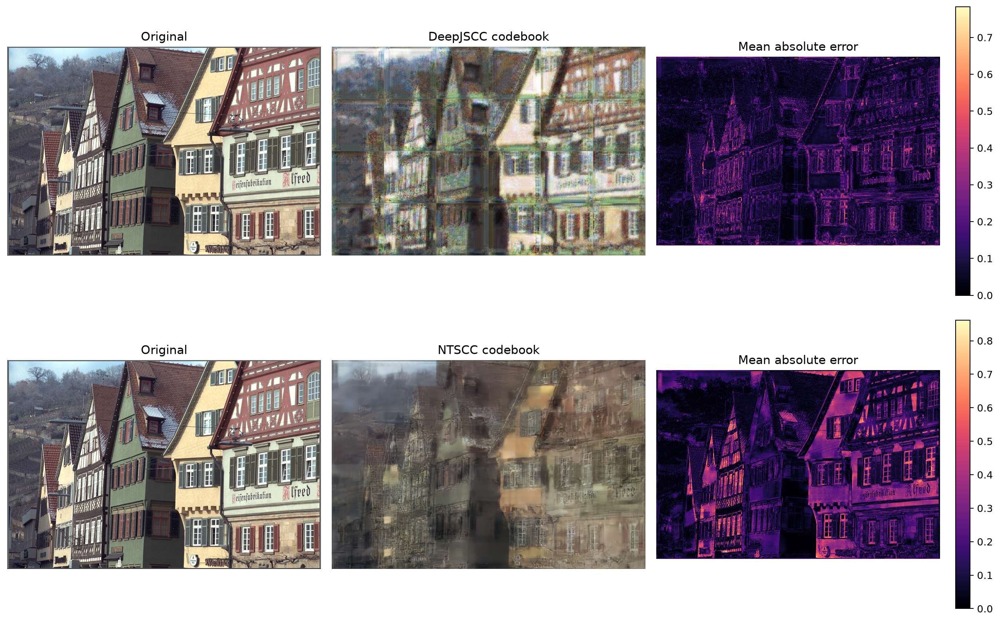

In [10]:
codebook_plot = session.plot_codebook_reconstructions()
display(DisplayImage(filename=str(codebook_plot)))

## 5. Final repaired comparison

`N/A` is used where a quantity has no valid interpretation. In particular, native analog JSCC has no payload-bit compression ratio, and NTSCC entropy BPP is not promoted to actual transmitted radio bits.

,Method,Category,Payload bits,Coded bits,Complex channel uses,CBR,Compression vs RAW,Bit reduction vs RAW (%),Channel-use saving vs RAW (%),Frame success rate,PSNR mean (dB),PSNR std,SSIM mean,LPIPS mean,CLIP cosine mean,Warning
0,RAW image,Source,9437184.0,N/A,N/A,N/A,1.0,0.0,N/A,N/A,inf,0.0,1.000000,0.000000,1.000000,Untransmitted source reference.
1,JPEG Q90,Codec only,1324216.0,N/A,N/A,N/A,7.12662,85.968102,N/A,N/A,36.230540,N/A,0.973055,0.006834,0.987068,Codec distortion only; no channel.
2,JPEG Q75,Codec only,813912.0,N/A,N/A,N/A,11.594846,91.375478,N/A,N/A,32.156016,N/A,0.943577,0.018946,0.985519,Codec distortion only; no channel.
3,JPEG Q50,Codec only,552960.0,N/A,N/A,N/A,17.066667,94.140625,N/A,N/A,29.425811,N/A,0.910267,0.043609,0.972427,Codec distortion only; no channel.
4,JPEG Q25,Codec only,366488.0,N/A,N/A,N/A,25.750322,96.116553,N/A,N/A,26.841379,N/A,0.861148,0.087909,0.951306,Codec distortion only; no channel.
5,RAW + LDPC/QPSK/AWGN,Digital PHY,9437184.0,18876416.0,9438208.0,8.000868,1.0,0.0,0.0,1.0,inf,0.0,1.000000,0.000000,1.000000,Metrics include successful CRC-valid frames on...
6,JPEG Q90 + LDPC/QPSK/AWGN,Digital PHY,1324216.0,2650112.0,1325056.0,1.123264,7.12662,85.968102,85.960725,1.0,36.230540,0.0,0.973055,0.006834,0.987068,Metrics include successful CRC-valid frames on...
7,JPEG Q75 + LDPC/QPSK/AWGN,Digital PHY,813912.0,1628160.0,814080.0,0.690104,11.594846,91.375478,91.374634,1.0,32.156016,0.0,0.943577,0.018946,0.985519,Metrics include successful CRC-valid frames on...
8,JPEG Q50 + LDPC/QPSK/AWGN,Digital PHY,552960.0,1107968.0,553984.0,0.469618,17.066667,94.140625,94.130411,1.0,29.425811,0.0,0.910267,0.043609,0.972427,Metrics include successful CRC-valid frames on...
9,JPEG Q25 + LDPC/QPSK/AWGN,Digital PHY,366488.0,733184.0,366592.0,0.310764,25.750322,96.116553,96.115873,1.0,26.841379,0.0,0.861148,0.087909,0.951306,Metrics include successful CRC-valid frames on...


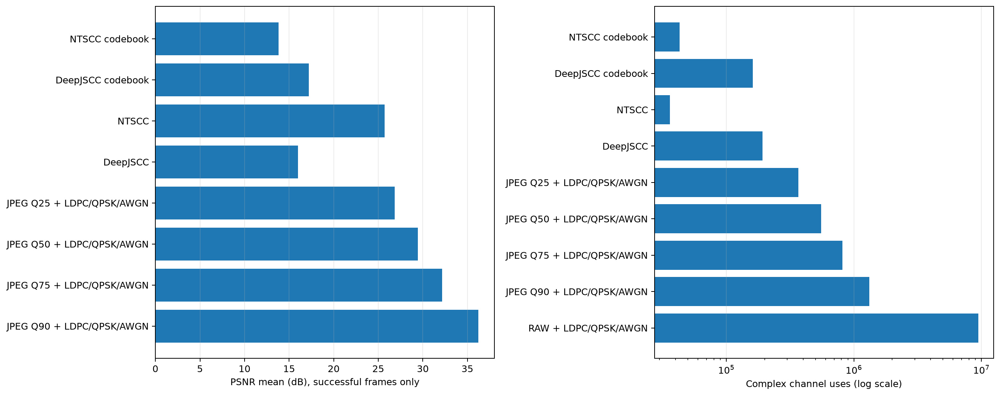

Results: D:\<local OneDrive>\Desktop\image_semcom\benchmark_outputs\final_repaired


In [11]:
final_table = session.comparison_table()
display(final_table.fillna('N/A'))
comparison_plot = session.plot_comparison(final_table)
display(DisplayImage(filename=str(comparison_plot)))
print(f'Results: {session.output_dir}')

## 6. Final presentation plots (measured outputs only)

These figures read `benchmark_outputs/final_repaired/final_comparison.csv` only. They do not rerun a model, metric network, LDPC decoder or channel. JPEG quality bars are codec-only; JPEG channel-resource bars explicitly represent JPEG + LDPC/QPSK/AWGN. RAW is an exact reconstruction and is not assigned a fabricated finite PSNR. LPIPS and CLIP remain in the detailed table.

,Method,Category,Payload bits,Coded bits,Complex channel uses,CBR,Compression vs RAW,Bit reduction vs RAW (%),Channel-use saving vs RAW (%),Frame success rate,PSNR mean (dB),PSNR std,SSIM mean,LPIPS mean,CLIP cosine mean,Warning
Method,,,,,,,,,,,,,,,,
RAW image,RAW image,Source,9437184.0,N/A,N/A,N/A,1.0,0.0,N/A,N/A,inf,0.0,1.000000,0.000000,1.000000,Untransmitted source reference.
JPEG Q90,JPEG Q90,Codec only,1324216.0,N/A,N/A,N/A,7.12662,85.968102,N/A,N/A,36.230540,N/A,0.973055,0.006834,0.987068,Codec distortion only; no channel.
JPEG Q75,JPEG Q75,Codec only,813912.0,N/A,N/A,N/A,11.594846,91.375478,N/A,N/A,32.156016,N/A,0.943577,0.018946,0.985519,Codec distortion only; no channel.
JPEG Q50,JPEG Q50,Codec only,552960.0,N/A,N/A,N/A,17.066667,94.140625,N/A,N/A,29.425811,N/A,0.910267,0.043609,0.972427,Codec distortion only; no channel.
JPEG Q25,JPEG Q25,Codec only,366488.0,N/A,N/A,N/A,25.750322,96.116553,N/A,N/A,26.841379,N/A,0.861148,0.087909,0.951306,Codec distortion only; no channel.
RAW + LDPC/QPSK/AWGN,RAW + LDPC/QPSK/AWGN,Digital PHY,9437184.0,18876416.0,9438208.0,8.000868,1.0,0.0,0.0,1.0,inf,0.0,1.000000,0.000000,1.000000,Metrics include successful CRC-valid frames on...
JPEG Q90 + LDPC/QPSK/AWGN,JPEG Q90 + LDPC/QPSK/AWGN,Digital PHY,1324216.0,2650112.0,1325056.0,1.123264,7.12662,85.968102,85.960725,1.0,36.230540,0.0,0.973055,0.006834,0.987068,Metrics include successful CRC-valid frames on...
JPEG Q75 + LDPC/QPSK/AWGN,JPEG Q75 + LDPC/QPSK/AWGN,Digital PHY,813912.0,1628160.0,814080.0,0.690104,11.594846,91.375478,91.374634,1.0,32.156016,0.0,0.943577,0.018946,0.985519,Metrics include successful CRC-valid frames on...
JPEG Q50 + LDPC/QPSK/AWGN,JPEG Q50 + LDPC/QPSK/AWGN,Digital PHY,552960.0,1107968.0,553984.0,0.469618,17.066667,94.140625,94.130411,1.0,29.425811,0.0,0.910267,0.043609,0.972427,Metrics include successful CRC-valid frames on...


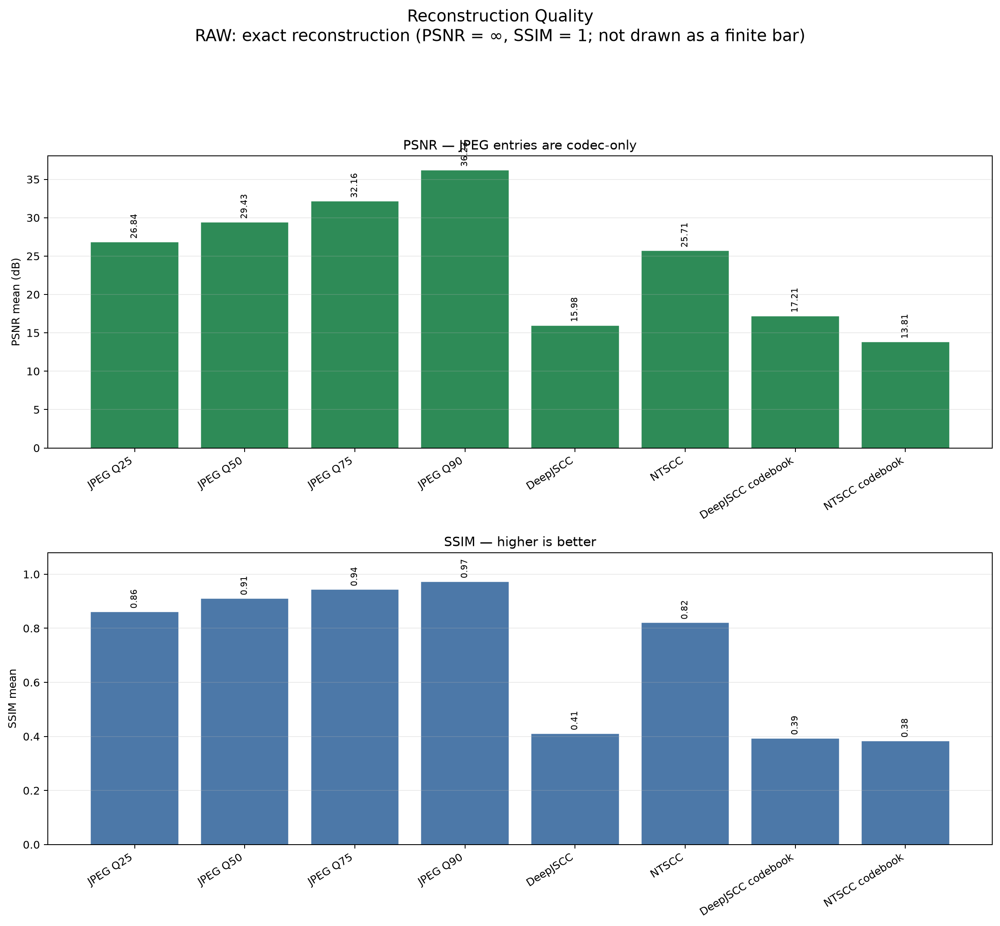

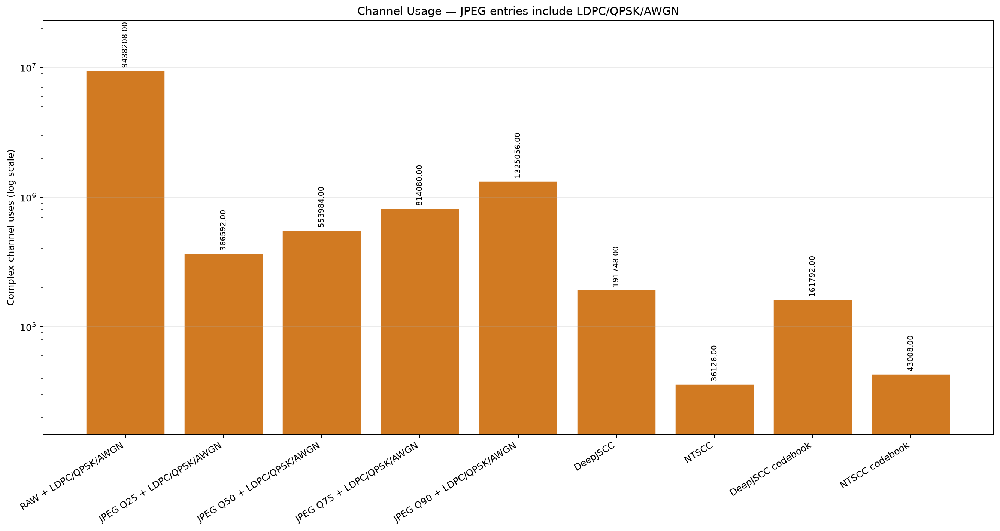

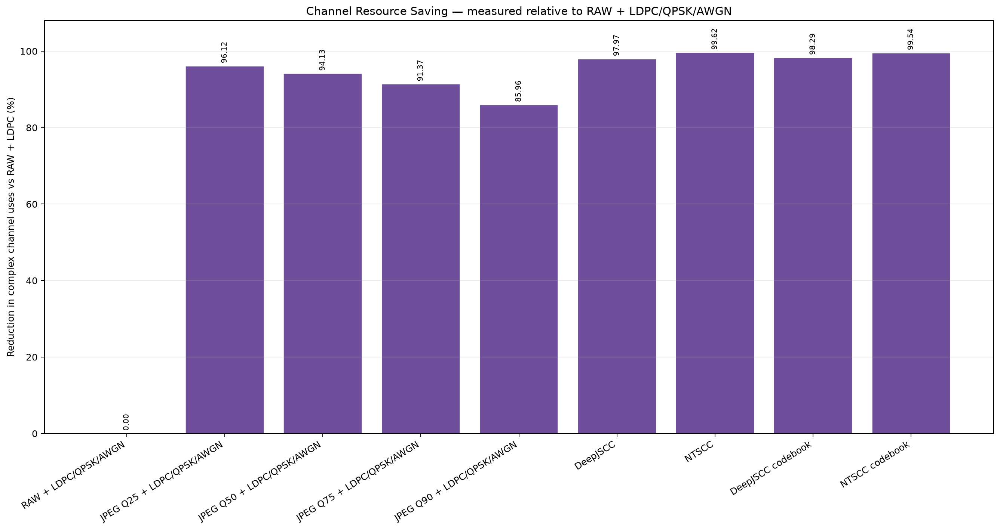

{'reconstruction_quality': 'D:\\<local OneDrive>\\Desktop\\image_semcom\\benchmark_outputs\\final_repaired\\presentation_reconstruction_quality.png',
 'channel_usage': 'D:\\<local OneDrive>\\Desktop\\image_semcom\\benchmark_outputs\\final_repaired\\presentation_channel_usage.png',
 'channel_resource_saving': 'D:\\<local OneDrive>\\Desktop\\image_semcom\\benchmark_outputs\\final_repaired\\presentation_channel_resource_saving.png'}

In [12]:
from pathlib import Path
from IPython.display import display, Image as DisplayImage
from semcom_benchmark.reporting import load_measured_comparison, generate_measured_comparison_plots
validated_output_dir = Path.cwd() / 'benchmark_outputs' / 'final_repaired'
measured_table = load_measured_comparison(validated_output_dir)
presentation_plot_paths = generate_measured_comparison_plots(validated_output_dir)
display(measured_table.fillna('N/A'))
for plot_path in presentation_plot_paths.values():
    display(DisplayImage(filename=plot_path))
presentation_plot_paths

## 7. Consolidated measured comparison and requested figures

All values below come from this execution. `N/A` is retained where a bit count or latent representation is not mathematically defined.


,Model,Algorithm,Original image packets,Latent representation units,CBR,PSNR (dB),SSIM,LPIPS,Reconstruction bits,Latent bits,Compression/payload bits,Complex channel uses,Computational complexity,Measured latency (s),Notes
0,RAW,8-bit RGB + CRC + rate-1/2 LDPC + QPSK + AWGN,1,N/A,8.000868,inf,1.000000,0.000000,9437184,N/A,9437184.0,9438208,LDPC decoding is iterative in coded blocks and...,275.233631,No latent representation; one channel trial.
1,JPEG Q90,JPEG quality 90 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,1.123264,36.230540,0.973055,0.006834,9437184,N/A,1324216.0,1325056,Block-DCT JPEG plus iterative LDPC decoding,192.334255,Compressed payload bits are not latent-model b...
2,JPEG Q75,JPEG quality 75 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.690104,32.156016,0.943577,0.018946,9437184,N/A,813912.0,814080,Block-DCT JPEG plus iterative LDPC decoding,94.444091,Compressed payload bits are not latent-model b...
3,JPEG Q50,JPEG quality 50 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.469618,29.425811,0.910267,0.043609,9437184,N/A,552960.0,553984,Block-DCT JPEG plus iterative LDPC decoding,32.784179,Compressed payload bits are not latent-model b...
4,JPEG Q25,JPEG quality 25 + CRC + rate-1/2 LDPC + QPSK +...,1,N/A,0.310764,26.841379,0.861148,0.087909,9437184,N/A,366488.0,366592,Block-DCT JPEG plus iterative LDPC decoding,22.463632,Compressed payload bits are not latent-model b...
5,DeepJSCC,Tiled learned analog JSCC,24,20184.0,0.162547,15.983024,0.410914,0.702314,9437184,N/A,N/A,191748,Encoder/decoder neural inference per image tile,22.144666,Continuous channel symbols have no mathematica...
6,NTSCC,Rate-adaptive nonlinear transform source-chann...,1,1536.0,0.030624,25.705845,0.820711,0.169477,9437184,312749.869629,312749.869629,36126,Analysis/hyperprior/rate-adapter/decoder neura...,51.768804,"Entropy-estimated bits are diagnostic, not tra..."
7,DeepJSCC codebook,K=256 full-token vector quantization + LDPC/QP...,24,20184.0,0.137153,17.214867,0.393513,0.609005,9437184,161472.0,161632.0,161792,K-means nearest-centroid search O(N*K*D) plus ...,12.299274,Payload also includes packet metadata and CRC.
8,NTSCC codebook,K=256 active-prefix PQ16 + rate map + LDPC/QPS...,1,4517.0,0.036458,13.807251,0.383858,0.517441,9437184,36136.0,42440.0,43008,Active-block K-means search O(N_active*K*16) p...,20.813137,Only active prefix blocks are clustered; paylo...


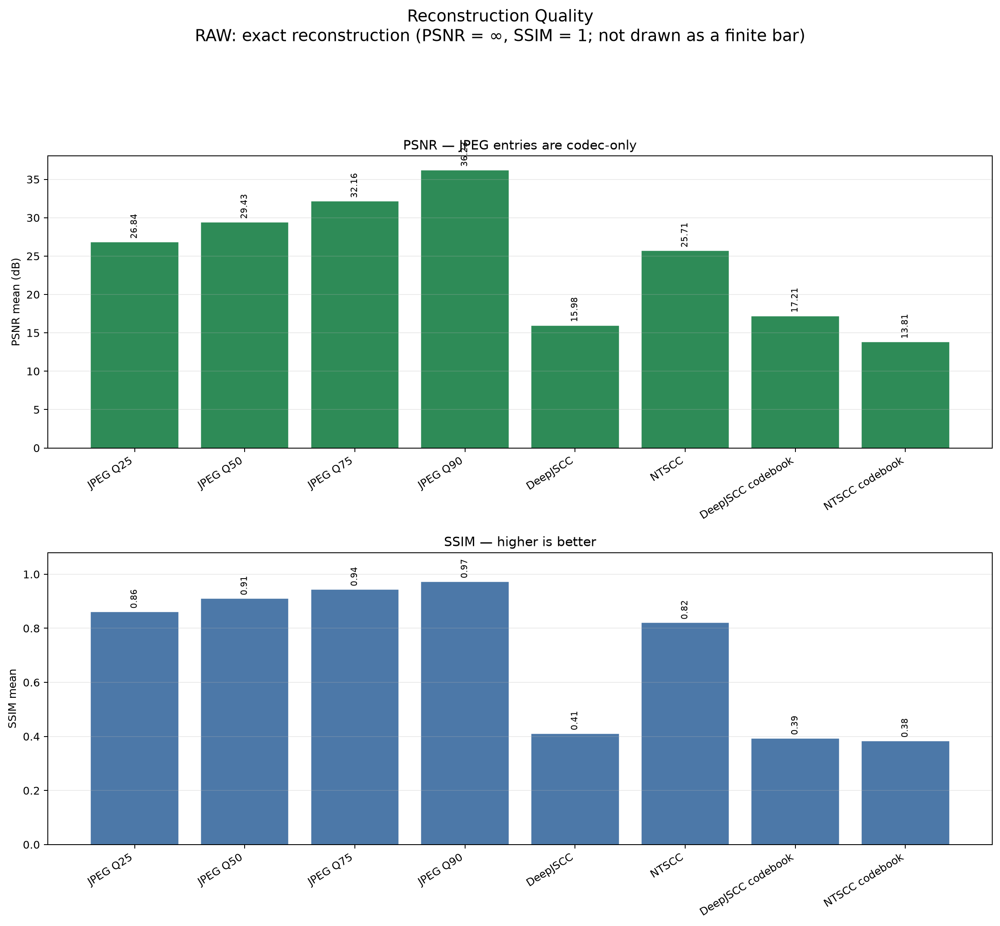

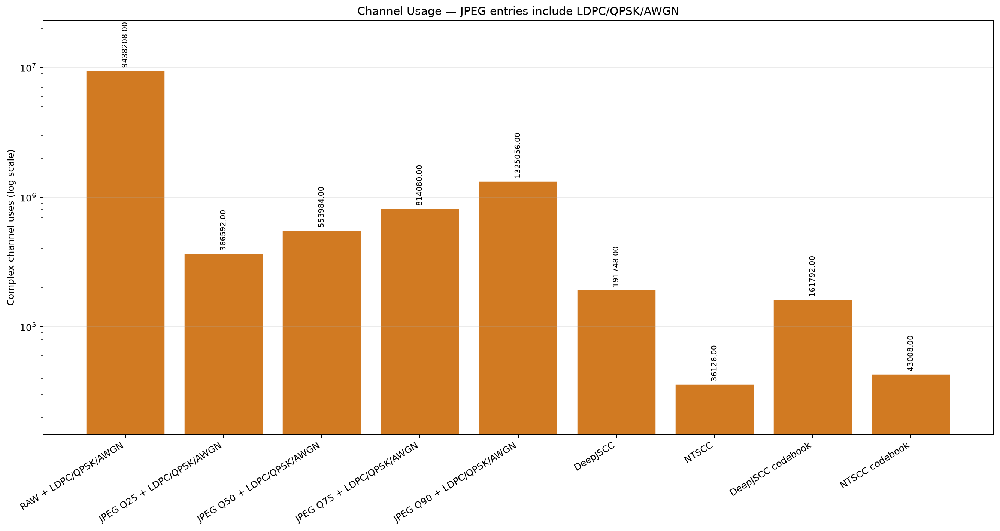

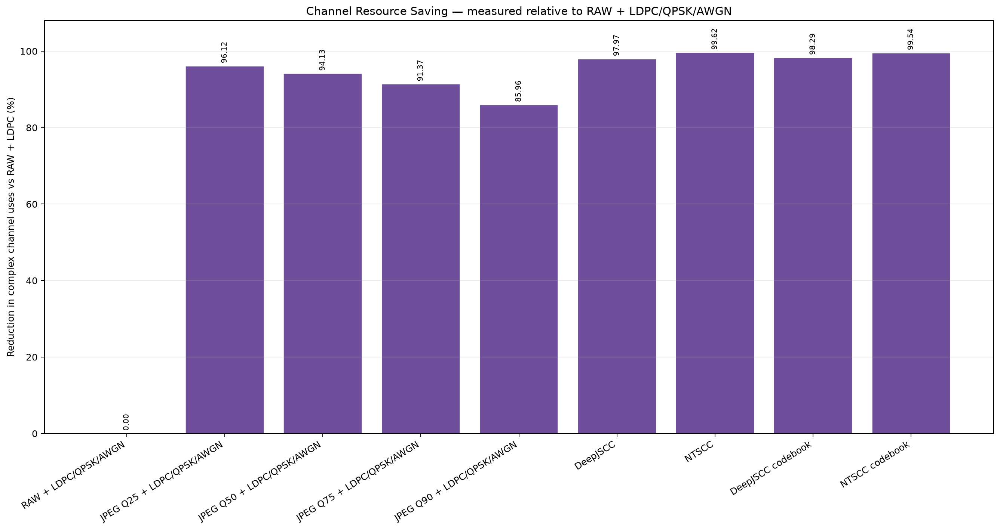

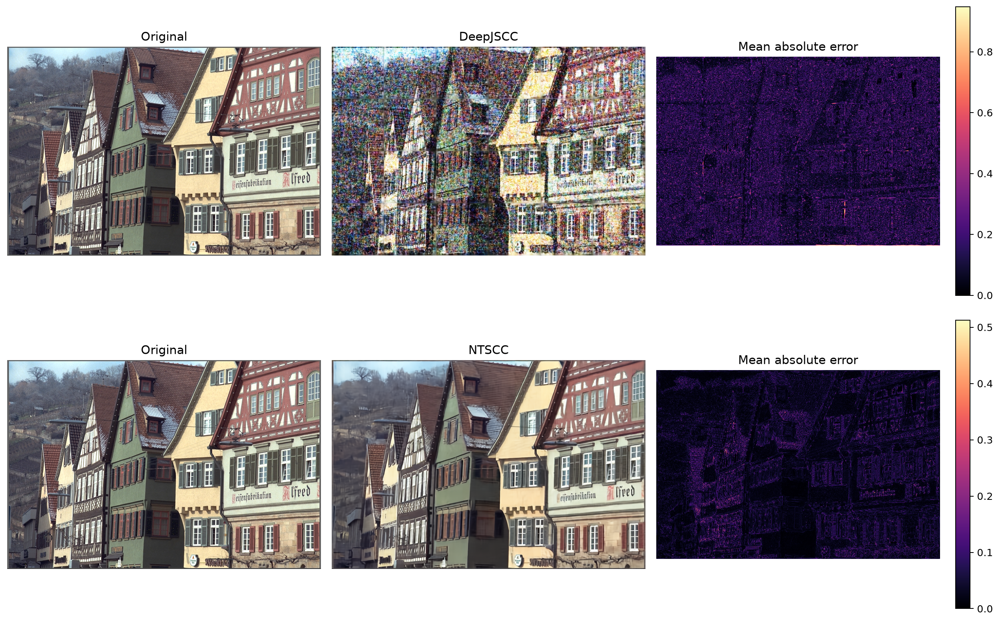

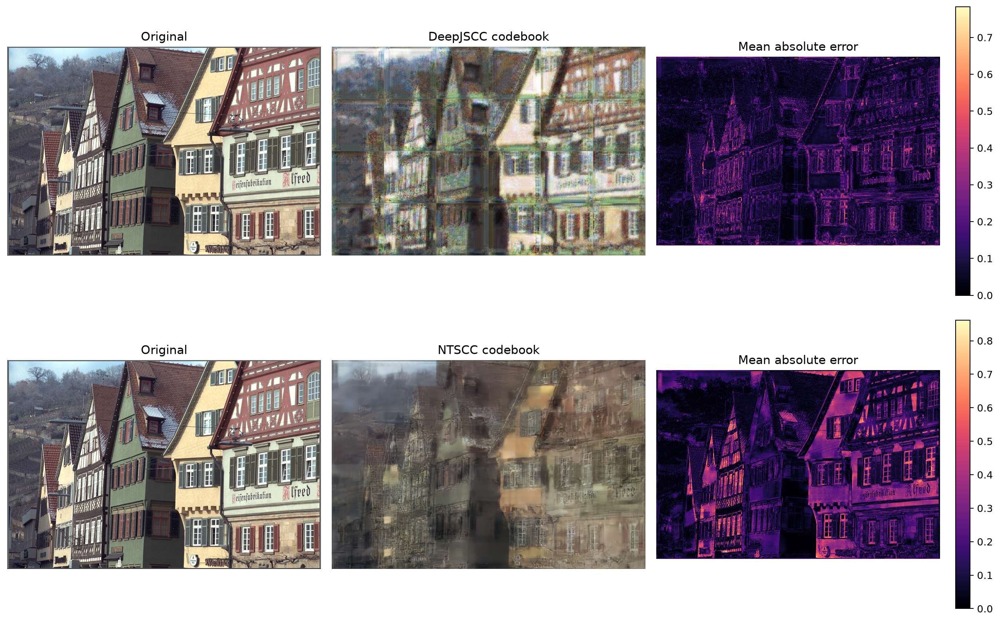

In [13]:
consolidated = session.consolidated_table()
display(consolidated.fillna('N/A'))
display(DisplayImage(filename=str(session.output_dir / 'presentation_reconstruction_quality.png')))
display(DisplayImage(filename=str(session.output_dir / 'presentation_channel_usage.png')))
display(DisplayImage(filename=str(session.output_dir / 'presentation_channel_resource_saving.png')))
display(DisplayImage(filename=str(session.output_dir / 'native_reconstructions.png')))
display(DisplayImage(filename=str(session.output_dir / 'codebook_reconstructions.png')))
